# 2. The MCDM layer
> How trufl ranks units from criteria, and splits a budget by rank

Part of a temporary series explaining the scoring work on the `scoring-experiments` branch: 1 campaigns, 2 MCDM, 3 scoring, 4 the sawtooth, 5 from `bayes` to `voi`. This notebook uses trufl's own `normalize`, `Optimizer` and `rank_to_sample` on a table of five units small enough to follow by hand.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from trufl.mcdm import normalize, score
from trufl.optimizer import Optimizer
from trufl.sampler import rank_to_sample

## The state table

Each row is a unit, each column a criterion. `Max` is the highest value measured, `Count` the number of samples, `Prior` an airborne survey's estimate, and `Population` the people living there. Unit E has no samples yet, so its `Max` and `Count` are missing:

In [ ]:
state = pd.DataFrame({'Max': [0.9, 0.4, 0.7, 0.2, np.nan], 'Count': [8, 3, 2, 5, np.nan],
                      'Prior': [0.8, 0.5, 0.6, 0.1, 0.4], 'Population': [200, 5000, 800, 300, 1500]},
                     index=pd.Index(list('ABCDE'), name='loc_id'))
state

,Max,Count,Prior,Population
loc_id,,,,
A,0.9,8.0,0.8,200
B,0.4,3.0,0.5,5000
C,0.7,2.0,0.6,800
D,0.2,5.0,0.1,300
E,NaN,NaN,0.4,1500


## Benefit or cost

A benefit criterion raises a unit's priority when it is high: a high `Max`, `Prior` or `Population` calls for more samples. A cost criterion raises priority when it is low: a unit with few samples (`Count`) needs more. This is the first thing a decision maker states:

In [ ]:
is_benefit = [True, False, True, True]

## Normalisation

The criteria have different units: a dose, a count, a number of people. `LINEAR1` puts them on one scale. A benefit criterion is divided by its column maximum, so the best unit gets 1. A cost criterion becomes the column minimum divided by the value, so the unit with the fewest samples gets 1. Every criterion then reads "higher is more urgent". Missing values stay missing:

In [ ]:
z, _ = normalize(state.values, is_benefit, 'LINEAR1')
pd.DataFrame(z, index=state.index, columns=state.columns).round(2)

,Max,Count,Prior,Population
loc_id,,,,
A,1.00,0.25,1.00,0.04
B,0.44,0.67,0.62,1.00
C,0.78,1.00,0.75,0.16
D,0.22,0.40,0.12,0.06
E,NaN,NaN,0.50,0.30


`LINEAR1` refuses negative values, and refuses a zero minimum for a cost criterion, because it divides by them. This is why the experiments use dose rates rather than their logarithms, and why a significant negative Moran's I stopped a run.

`Optimizer.get_rank` then replaces each missing value with 1, the highest priority. A unit with no samples is treated as urgent on every criterion it lacks:

In [ ]:
z_filled = np.where(np.isnan(z), 1.0, z)
pd.DataFrame(z_filled, index=state.index, columns=state.columns).round(2)

,Max,Count,Prior,Population
loc_id,,,,
A,1.00,0.25,1.00,0.04
B,0.44,0.67,0.62,1.00
C,0.78,1.00,0.75,0.16
D,0.22,0.40,0.12,0.06
E,1.00,1.00,0.50,0.30


## Weights and the CP score

Weights say how much each criterion counts; they sum to 1. Compromise programming (`CP`) multiplies each column by its weight, takes the best value of each column as the ideal unit, and scores each unit by its distance to that ideal. A lower score means a higher priority:

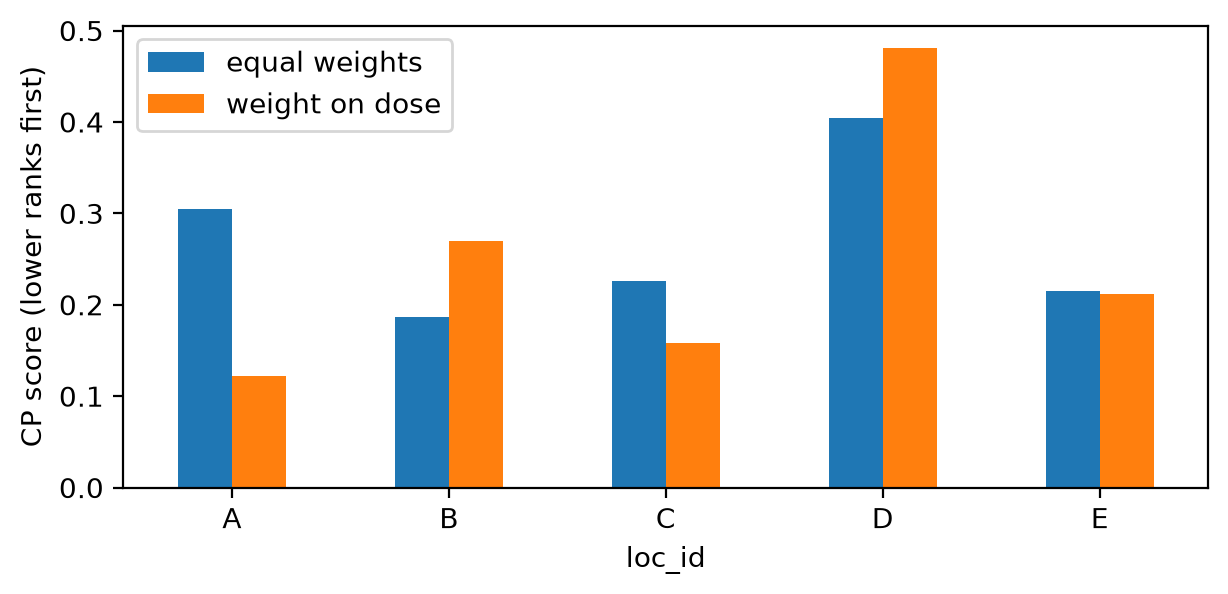

In [ ]:
def cp_scores(weights):
    s, _ = score(z_filled, [True] * 4, weights, 'CP')
    return pd.Series(s, index=state.index)

equal_w = [0.25, 0.25, 0.25, 0.25]
dose_w = [0.4, 0.1, 0.4, 0.1]
scores = pd.DataFrame({'equal weights': cp_scores(equal_w), 'weight on dose': cp_scores(dose_w)})
ax = scores.plot.bar(figsize=(7, 3), rot=0)
ax.set(ylabel='CP score (lower ranks first)');

The weights decide the ranking. With equal weights, B ranks first, because of its population. With most of the weight on `Max` and `Prior`, A ranks first. E ranks high in both, because its missing values count as top priority. `Optimizer.get_rank` does all of the above in one call:

In [ ]:
ranks = pd.DataFrame({name: Optimizer(state).get_rank(is_benefit_x=is_benefit, w_vector=w, n_method='LINEAR1', s_method='CP')['rank']
                      for name, w in {'equal weights': equal_w, 'weight on dose': dose_w}.items()})
ranks.sort_values('equal weights')

,equal weights,weight on dose
loc_id,,
B,1,4
E,2,3
C,3,2
A,4,1
D,5,5


## From ranks to samples

`rank_to_sample` turns ranks into a number of samples per unit. The `quantiles` policy, used in the how-to, splits the units into four quartiles by rank. The first quartile shares 50% of the budget, the second 30%, the third 20% and the last none. With eight units and 20 samples:

In [ ]:
ranks8 = np.arange(1, 9)
rank_to_sample(ranks8, budget=20, policy='quantiles')

array([5, 5, 3, 3, 2, 2, 0, 0])

Each quartile's share is divided among its units and rounded down. Some budgets are then not spent: with 24 samples, the same eight units get 22. In the experiments, with 100 units and no minimum, it allocates 125 of 150 samples. This is recorded in `scoring-plan.md`:

In [ ]:
int(rank_to_sample(ranks8, budget=24, policy='quantiles').sum())

22

## Two jobs in one weighted sum

The state table mixes two kinds of criteria:

- Value criteria say what is at stake: `Population`, and `Prior` or `Max` read as severity. Decision makers have views on how these trade off, and MCDM makes those trade-offs explicit and open to challenge.
- Information criteria say what we do not know yet: `Count`, a standard deviation, Moran's I. Nobody has a view on "`Count` weighs 0.1"; that weight is a technical setting.

In the experiments, strategies that target the probability of a wrong decision directly did better than the how-to MCDM strategy (notebooks 3 and 5). Part of that gap comes from `rank_to_sample` spending less of the budget, so it overstates how much worse MCDM is at this job. `scoring-design.md` proposes keeping MCDM for the first job, turning its score into a stake weight per unit, and leaving the allocation to an information layer.